# Heart Disease Prediction System

**Course:** Machine Learning Fundamentals  
**Assignment:** Assignment 2, Developing an End-to-End Machine Learning System

## Project Overview

The objective of this project is to develop a machine learning system that predicts the presence of heart disease using selected patient attributes. The project includes dataset exploration, data preprocessing, model training, evaluation, and deployment through a Streamlit web application.

The system is developed for educational purposes and is not intended to replace professional medical diagnosis.

In [11]:
import pandas as pd

# Define the column names for the Heart Disease dataset
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

# Load the dataset
df = pd.read_csv(
    "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

# Display the first five rows
print(df.head())


    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  


## 1. Dataset Loading

The Heart Disease dataset used in this project is obtained from the UCI Machine Learning Repository. The Cleveland subset is loaded into a Pandas DataFrame, and meaningful column names are assigned to make the attributes easier to understand.

Missing values represented by `?` are converted to `NaN` so they can be identified and handled during data preprocessing.

In [12]:

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column data types and missing values
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Display basic statistical information
print("\nStatistical summary:")
print(df.describe())


Dataset shape: (303, 14)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          

## 2. Dataset Overview and Initial Analysis

The dataset is inspected to understand its dimensions, data types, missing values, and statistical characteristics. This initial analysis helps identify potential preprocessing requirements before training the machine learning model.

The results of the inspection will guide the handling of missing data and the selection of input features for the prediction system.

## 3. Data Preprocessing

Data preprocessing is an important step in machine learning because raw datasets may contain missing or unsuitable values. The Cleveland Heart Disease dataset represents some missing values with `?`, which were converted to `NaN` during data loading.

In this step, we will identify missing values and remove records containing them to prepare a clean dataset for model training.

In [13]:

# Display the number of missing values in each column
print("Missing values before preprocessing:")
print(df.isnull().sum())

# Display the dataset size before removing missing values
print("\nDataset shape before preprocessing:", df.shape)

# Remove rows containing missing values
df = df.dropna()

# Reset the row index after removing missing records
df = df.reset_index(drop=True)

# Display the number of missing values after preprocessing
print("\nMissing values after preprocessing:")
print(df.isnull().sum())

# Display the cleaned dataset size
print("\nDataset shape after preprocessing:", df.shape)


Missing values before preprocessing:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Dataset shape before preprocessing: (303, 14)

Missing values after preprocessing:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Dataset shape after preprocessing: (297, 14)


### 3.1 Explanation of Missing Value Handling

The missing values were handled using the `dropna()` function, which removes records containing missing entries. The dataset index was then reset to maintain sequential row numbering.

Removing incomplete records allows us to train the model using complete observations. However, this also reduces the dataset size, so the number of remaining records should be checked before proceeding.

### 3.2 Target Variable Analysis

The original target variable contains five possible values, from 0 to 4. To make the system a binary classifier, these values will be grouped into two categories. A value of 0 represents the absence of heart disease, while values greater than 0 represent its presence.

In [14]:

# Display the original target value distribution
print("Original target distribution:")
print(df["target"].value_counts().sort_index())

# Convert the target into two classes
df["target"] = (df["target"] > 0).astype(int)

# Display the new binary target distribution
print("\nBinary target distribution:")
print(df["target"].value_counts().sort_index())

# Display the cleaned dataset
print("\nFirst five rows of the cleaned dataset:")
print(df.head())


Original target distribution:
target
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

Binary target distribution:
target
0    160
1    137
Name: count, dtype: int64

First five rows of the cleaned dataset:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  


## 4. Feature Selection

Feature selection involves choosing the input attributes that will be used by the machine learning model to make predictions.

For this project, four attributes are selected from the Cleveland Heart Disease dataset:

- **Age (`age`):** The patient's age in years.
- **Resting Blood Pressure (`trestbps`):** The patient's resting blood pressure.
- **Cholesterol (`chol`):** The patient's serum cholesterol level.
- **Maximum Heart Rate (`thalach`):** The maximum heart rate achieved by the patient.

The target variable is `target`, where 0 represents the absence of heart disease and 1 represents its presence.

These four features will be used as model inputs, while the target variable will be used as the output to predict.

In [15]:

# Select the four input features
X = df[["age", "trestbps", "chol", "thalach"]]

# Select the target variable
y = df["target"]

# Display the input features
print("Selected input features:")
print(X.head())

# Display the target values
print("\nTarget values:")
print(y.head())

# Display the dimensions of the input and target data
print("\nInput data shape:", X.shape)
print("Target data shape:", y.shape)


Selected input features:
    age  trestbps   chol  thalach
0  63.0     145.0  233.0    150.0
1  67.0     160.0  286.0    108.0
2  67.0     120.0  229.0    129.0
3  37.0     130.0  250.0    187.0
4  41.0     130.0  204.0    172.0

Target values:
0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64

Input data shape: (297, 4)
Target data shape: (297,)


## 5. Splitting the Dataset

The dataset is divided into training and testing subsets. The training data is used to teach the machine learning model, while the testing data is used to evaluate its performance on previously unseen records.

An 80:20 split is used, with 80% of the data for training and 20% for testing. Stratified sampling is applied to maintain approximately the same proportion of each target class in both subsets. A fixed random state is used to make the split reproducible.

In [16]:

# Import the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Divide the data into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of records in each subset
print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training input shape: (237, 4)
Testing input shape: (60, 4)

Training target shape: (237,)
Testing target shape: (60,)


### 5.1 Explanation of the Data Split

The `train_test_split()` function divides the selected features and target values into training and testing sets. The `test_size=0.20` parameter reserves 20% of the records for testing, while `random_state=42` ensures the same split can be reproduced. The `stratify=y` parameter helps preserve the class distribution in both subsets.

The testing data will remain separate from model training so that evaluation provides a more meaningful estimate of performance on unseen records.

## 6. Model Training

In this step, a Support Vector Classifier (SVC) is used to train the Heart Disease Prediction System. SVC is a supervised machine learning algorithm that learns patterns from labeled training data and uses those patterns to classify new observations.

The model is trained using four input features: age, resting blood pressure, cholesterol, and maximum heart rate. The target variable indicates whether heart disease is absent or present.

Feature scaling is applied before training because SVC can be sensitive to differences in the ranges of input features. A pipeline is used to ensure that scaling is learned only from the training data and then applied consistently to the testing data and future predictions.

In [17]:

# Import the required machine learning tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create a machine learning pipeline
heart_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=1.0))
])

# Train the model using the training dataset
heart_model.fit(X_train, y_train)

# Display a confirmation message
print("Heart Disease Prediction Model trained successfully!")

# Display the number of input features used by the model
print("Number of input features:", heart_model.n_features_in_)
print("Input features:", list(X.columns))


Heart Disease Prediction Model trained successfully!
Number of input features: 4
Input features: ['age', 'trestbps', 'chol', 'thalach']


### 6.1 Training Results

The Support Vector Classifier was trained using the training subset of the dataset. A pipeline combines feature scaling and classification into a single workflow, ensuring that the same preprocessing is applied during both training and prediction.

The trained model uses four input features to classify each record into one of two categories: absence or presence of heart disease. Its performance will be assessed using the separate testing dataset in the next section.

## 7. Model Evaluation

Model evaluation measures how effectively the trained machine learning model predicts outcomes for unseen data. In this project, the model is evaluated using the testing dataset, which was kept separate during training.

The evaluation uses accuracy, precision, recall, F1-score, and a confusion matrix. These metrics provide a more complete understanding of the model's performance than accuracy alone.

Model Accuracy: 76.67%

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.75      0.84      0.79        32
   Heart Disease       0.79      0.68      0.73        28

        accuracy                           0.77        60
       macro avg       0.77      0.76      0.76        60
    weighted avg       0.77      0.77      0.76        60

Confusion Matrix:
[[27  5]
 [ 9 19]]


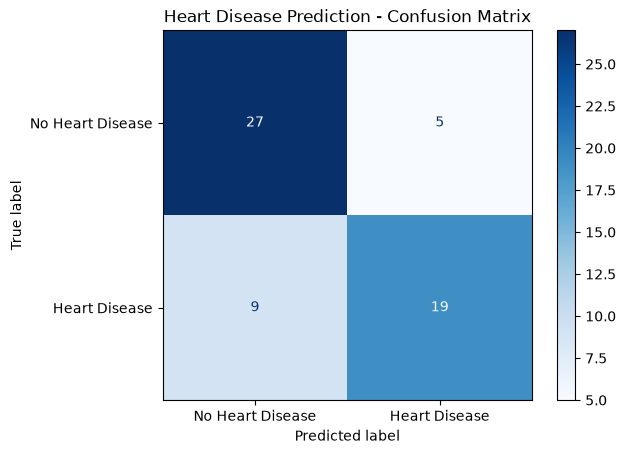

In [21]:

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict target values for the test dataset
y_pred = heart_model.predict(X_test)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display the accuracy
print(f"Model Accuracy: {accuracy:.2%}")

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    )
)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.show()


### 7.1 Evaluation Metrics

- **Accuracy:** The proportion of all test records classified correctly.
- **Precision:** The proportion of records predicted as a particular class that actually belong to that class.
- **Recall:** The proportion of actual records in a class that the model correctly identifies.
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion Matrix:** Shows correct and incorrect predictions for both classes.

For this binary classification task, class 0 represents no heart disease and class 1 represents the presence of heart disease.

The confusion matrix and classification report help identify the types of errors made by the model. In a medical prediction context, false negatives are particularly important because they represent cases where heart disease is present but the model predicts its absence.

## 8. Saving the Trained Model

After training and evaluating the model, it is saved to a file so it can be reused in the Streamlit web application. Saving the trained pipeline preserves both the feature-scaling step and the Support Vector Classifier.

The saved model can then be loaded to make predictions on new patient inputs without repeating the training process.

In [22]:

# Import joblib to save the trained model
import joblib

# Save the trained pipeline to a file
joblib.dump(heart_model, "heart_disease_model.pkl")

print("Model saved successfully as heart_disease_model.pkl")


Model saved successfully as heart_disease_model.pkl


### 8.1 Saved Model

The trained model has been saved as `heart_disease_model.pkl`. The file contains the complete preprocessing and classification pipeline, including the fitted feature scaler and SVC classifier.

This file will be used by the Streamlit application to generate predictions from four user-provided attributes.